<a href="https://colab.research.google.com/github/asema405/Maachine_Learning/blob/main/ML_PR5_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

sns.set_theme(style="whitegrid")
print("Китепканалар ийгиликтүү жүктөлдү!")

Китепканалар ийгиликтүү жүктөлдү!


In [27]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

print("Датасеттин өлчөмү:", df.shape)
display(df.head())

Датасеттин өлчөмү: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [28]:
print("Мамычалар:")
print(df.columns.tolist())

print("\nМаалымат түрлөрү:")
df.info()

print("\nБош маанилер:")
print(df.isnull().sum())

print("\nСандык статистика:")
display(df.describe())

Мамычалар:
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Маалымат түрлөрү:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB

Бош маанилер:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Сандык статистика:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


Класстардын саны:
high_tip
0    108
1    136
Name: count, dtype: int64

Класстардын үлүшү:
high_tip
0    0.443
1    0.557
Name: proportion, dtype: float64


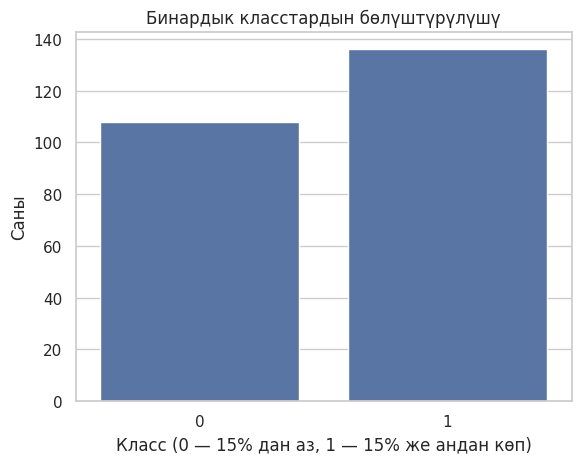

In [29]:

df["tip_rate"] = df["tip"] / df["total_bill"]

# 1 — чайпул эсептин 15% же андан көп
# 0 — чайпул эсептин 15% дан аз
df["high_tip"] = (df["tip_rate"] >= 0.15).astype(int)

print("Класстардын саны:")
print(df["high_tip"].value_counts().sort_index())

print("\nКласстардын үлүшү:")
print(df["high_tip"].value_counts(normalize=True).sort_index().round(3))

sns.countplot(data=df, x="high_tip")
plt.title("Бинардык класстардын бөлүштүрүлүшү")
plt.xlabel("Класс (0 — 15% дан аз, 1 — 15% же андан көп)")
plt.ylabel("Саны")
plt.show()

In [30]:
# Максаттуу белги
y = df["high_tip"]

# Модель колдоно турган белгилер
X = df[[
    "total_bill",
    "size",
    "sex",
    "smoker",
    "day",
    "time"
]]

numeric_features = ["total_bill", "size"]
categorical_features = ["sex", "smoker", "day", "time"]

print("X өлчөмү:", X.shape)
print("y өлчөмү:", y.shape)

X өлчөмү: (244, 6)
y өлчөмү: (244,)


In [31]:
# 60% — окутуу, 20% — validation, 20% — test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTrain класстары:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation класстары:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest класстары:")
print(y_test.value_counts(normalize=True).round(3))

Train: (146, 6)
Validation: (49, 6)
Test: (49, 6)

Train класстары:
high_tip
1    0.555
0    0.445
Name: proportion, dtype: float64

Validation класстары:
high_tip
1    0.551
0    0.449
Name: proportion, dtype: float64

Test класстары:
high_tip
1    0.571
0    0.429
Name: proportion, dtype: float64


In [32]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

print("Logistic Regression модели окутулду!")

Logistic Regression модели окутулду!


In [33]:
# 1-класстын ыктымалдыгы
y_val_proba = model.predict_proba(X_val)[:, 1]
y_test_proba = model.predict_proba(X_test)[:, 1]

# Демейки босого — 0.5
y_test_default = (y_test_proba >= 0.5).astype(int)

print("Биринчи 10 ыктымалдык:")
print(np.round(y_test_proba[:10], 3))

print("\nБиринчи 10 класс божомолу:")
print(y_test_default[:10])

Биринчи 10 ыктымалдык:
[0.67  0.839 0.552 0.461 0.731 0.297 0.664 0.616 0.441 0.572]

Биринчи 10 класс божомолу:
[1 1 1 0 1 0 1 1 0 1]


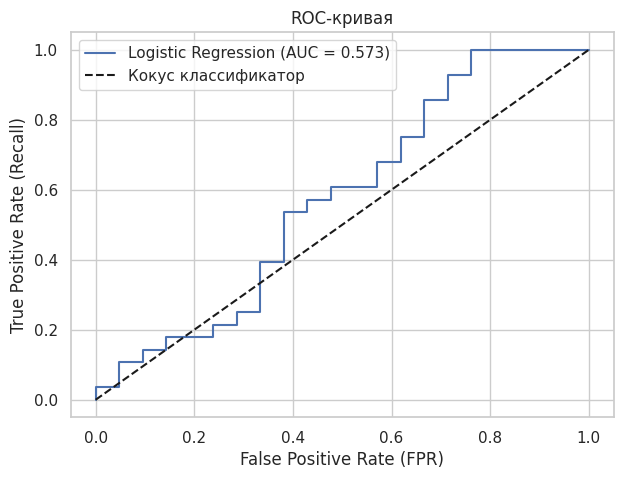

ROC-AUC: 0.573


In [34]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_proba)
roc_auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Кокус классификатор")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривая")
plt.legend()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")